In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath(".."))  # repository root (not needed after pip install -e .)

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

from data_generation import generate_contrasts, generate_design, generate_response
from psi_pt.inference import psi_pt_randj
from psi_pt.utils import construct_Sigma, construct_test_statistic, pivot

In [2]:
p, n0, ns, K = 100, 40, 100, 3
sigma = 1.0
h = 10.0
n_rep = 1000

In [3]:
rng = np.random.default_rng(1)

X0, X_list = generate_design(rng, p, n0, ns, K)
contrasts = generate_contrasts(rng, p, K, h)
beta0 = np.zeros(p)
beta0[:5] = 1.0

Sigma_0 = sigma ** 2 * np.eye(n0)
Sigma_K = [sigma ** 2 * np.eye(ns) for _ in range(K)]
Sigma = construct_Sigma(Sigma_0, Sigma_K)

In [4]:
def run(n_rep):
    pivots, n_empty = [], 0

    for i in range(1, n_rep + 1):
        y0, y_list = generate_response(rng, X0, X_list, sigma, beta0, contrasts)

        result = psi_pt_randj(X0, y0, X_list, y_list, Sigma_0, Sigma_K, rng=rng)

        if result["results"]:
            r = result["results"][0]
            Y = np.concatenate(y_list + [y0])
            etaj, etajTY = construct_test_statistic(r["feature"], X0, Y, result["selected_model"])
            # true value of the tested parameter (eta_j is zero on the sources)
            tn_mu = etaj[-n0:] @ (X0 @ beta0)
            pivots.append(pivot(r["intervals"], etajTY, etaj, Sigma, tn_mu))
        else:
            n_empty += 1

        if i % 50 == 0:
            print(f"{i}/{n_rep}, pivots: {len(pivots)}, empty models: {n_empty}")

    return np.array(pivots), n_empty

In [ ]:
list_pivot, _ = run(n_rep)

c:\Ananconda\Lib\site-packages\skglm\utils\anderson.py:43: RuntimeWarning: divide by zero encountered in divide
  C = inv_UTU_ones / np.sum(inv_UTU_ones)
c:\Ananconda\Lib\site-packages\skglm\utils\anderson.py:45: RuntimeWarning: invalid value encountered in matmul
  return self.arr_w_[:, 1:] @ C, self.arr_Xw_[:, 1:] @ C, True


50/1000, pivots: 50, empty models: 0


In [ ]:
statistic, p_value = stats.kstest(list_pivot, "uniform")
print(f"KS-Test statistic = {statistic:.4f}")
print(f"KS-Test p-value = {p_value:.4f}")

KS-Test statistic = 0.0570
KS-Test p-value = 0.5148


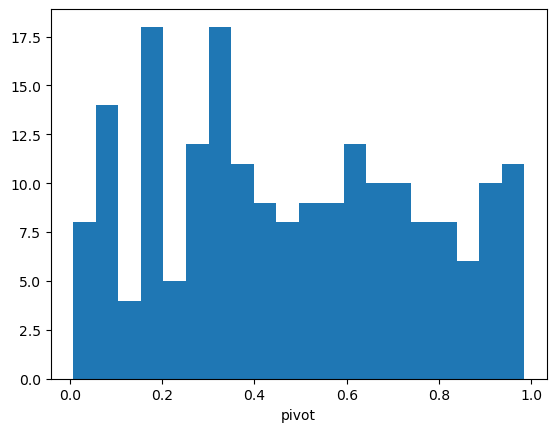

In [ ]:
plt.hist(list_pivot, bins=20)
plt.xlabel("pivot")
plt.show()

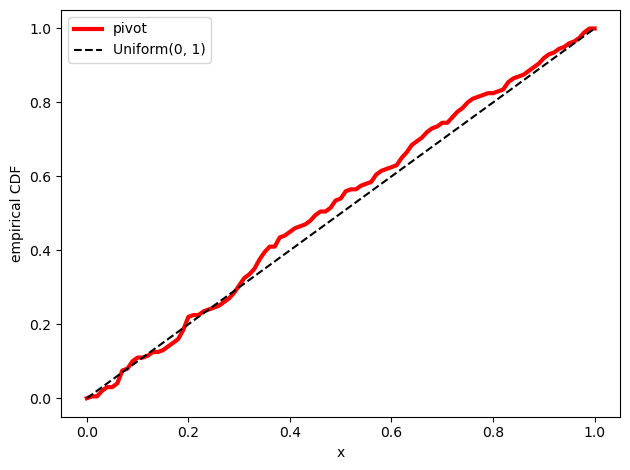

In [ ]:
grid = np.linspace(0, 1, 101)
ecdf = np.searchsorted(np.sort(list_pivot), grid, side="right") / len(list_pivot)
plt.plot(grid, ecdf, "r-", linewidth=3, label="pivot")
plt.plot([0, 1], [0, 1], "k--", label="Uniform(0, 1)")
plt.xlabel("x")
plt.ylabel("empirical CDF")
plt.legend()
plt.tight_layout()
plt.show()